# Progetto Prolog IALAB 2025/2026
Alessio Camerano - Matricola 1044444

## In cosa consiste

Il progetto confronta due strategie di ricerca su spazio degli stati: A* e IDA*. Le implementazioni lavorano su due domini distinti, il labirinto e l'8-puzzle, e usano un'euristica condivisa per guidare la ricerca verso il goal.

## Come e' stato fatto

- I motori di ricerca sono in `src/prolog/algoritmi/aStar.pl` e `src/prolog/algoritmi/idaStar.pl`.
- L'euristica condivisa e' in `src/prolog/euristica/euristica.pl`.
- I domini e le azioni sono separati in `src/prolog/domini/labirinto/` e `src/prolog/domini/puzzle/`.
- Il punto di ingresso Prolog e' `src/prolog/app/main.pl`.
- Gli script `tools/python/genera_prolog_maze.py` e `tools/python/visualizza_risultati.py` supportano la generazione e la visualizzazione dei risultati.

## Risultati

Il modello produce un percorso risolutivo per entrambi i domini e permette di confrontare tempo di calcolo e memoria. Sul labirinto, A* tende a essere piu' rapido ma piu' esigente in memoria, mentre IDA* riduce l'uso di RAM a costo di riespandere piu' volte gli stessi nodi. Nel puzzle dell'8 il divario si riduce, ma la stessa tendenza resta visibile.

## Nota sui file Python

Gli script in `tools/python/` non fanno parte del nucleo originale del progetto: sono stati aggiunti con l'aiuto di Copilot per generare il labirinto e visualizzare i risultati in modo piu' leggibile.

## Esempi estratti dai sorgenti Prolog

Di seguito sono riportati estratti dei file in `src/prolog/` che mostrano i punti chiave dell'implementazione: ingresso del sistema, motori di ricerca ed euristica.

### Punto di ingresso (src/prolog/app/main.pl)

```prolog
:- consult('src/prolog/algoritmi/aStar.pl').
:- consult('src/prolog/algoritmi/idaStar.pl').
:- consult('src/prolog/euristica/euristica.pl').
:- consult('src/prolog/domini/labirinto/labirinto.pl').
:- consult('src/prolog/domini/labirinto/labirinto_azioni.pl').
:- consult('src/prolog/domini/puzzle/puzzle.pl').
:- consult('src/prolog/domini/puzzle/puzzle_azioni.pl').
```

### A* (src/prolog/algoritmi/aStar.pl)

```prolog
cercaAStar(ListaAzioni, CostoTotale) :-
    iniziale(S0),
    euristica(S0, H0),
    F0 is H0,
    a_star_opt([F0-n(S0, [], [S0], 0)], ListaInv, CostoTotale),
    reverse(ListaInv, ListaAzioni).
```

### IDA* (src/prolog/algoritmi/idaStar.pl)

```prolog
cercaIDAStar(ListaAzioni) :-
    iniziale(S0),
    euristica(S0, SogliaIniziale),
    iterazione(S0, SogliaIniziale, [S0], ListaAzioni).
```

### Euristica (src/prolog/euristica/euristica.pl)

```prolog
euristica(Stato, H) :-
    findall(H1, costo_a_un_goal(Stato, H1), Costi),
    min_list(Costi, H).
```

## Labirinto: soluzione calcolata dai due algoritmi

La cella seguente mostra il labirinto usato per lo studio con anche la soluzione trovata dai due algoritmi.

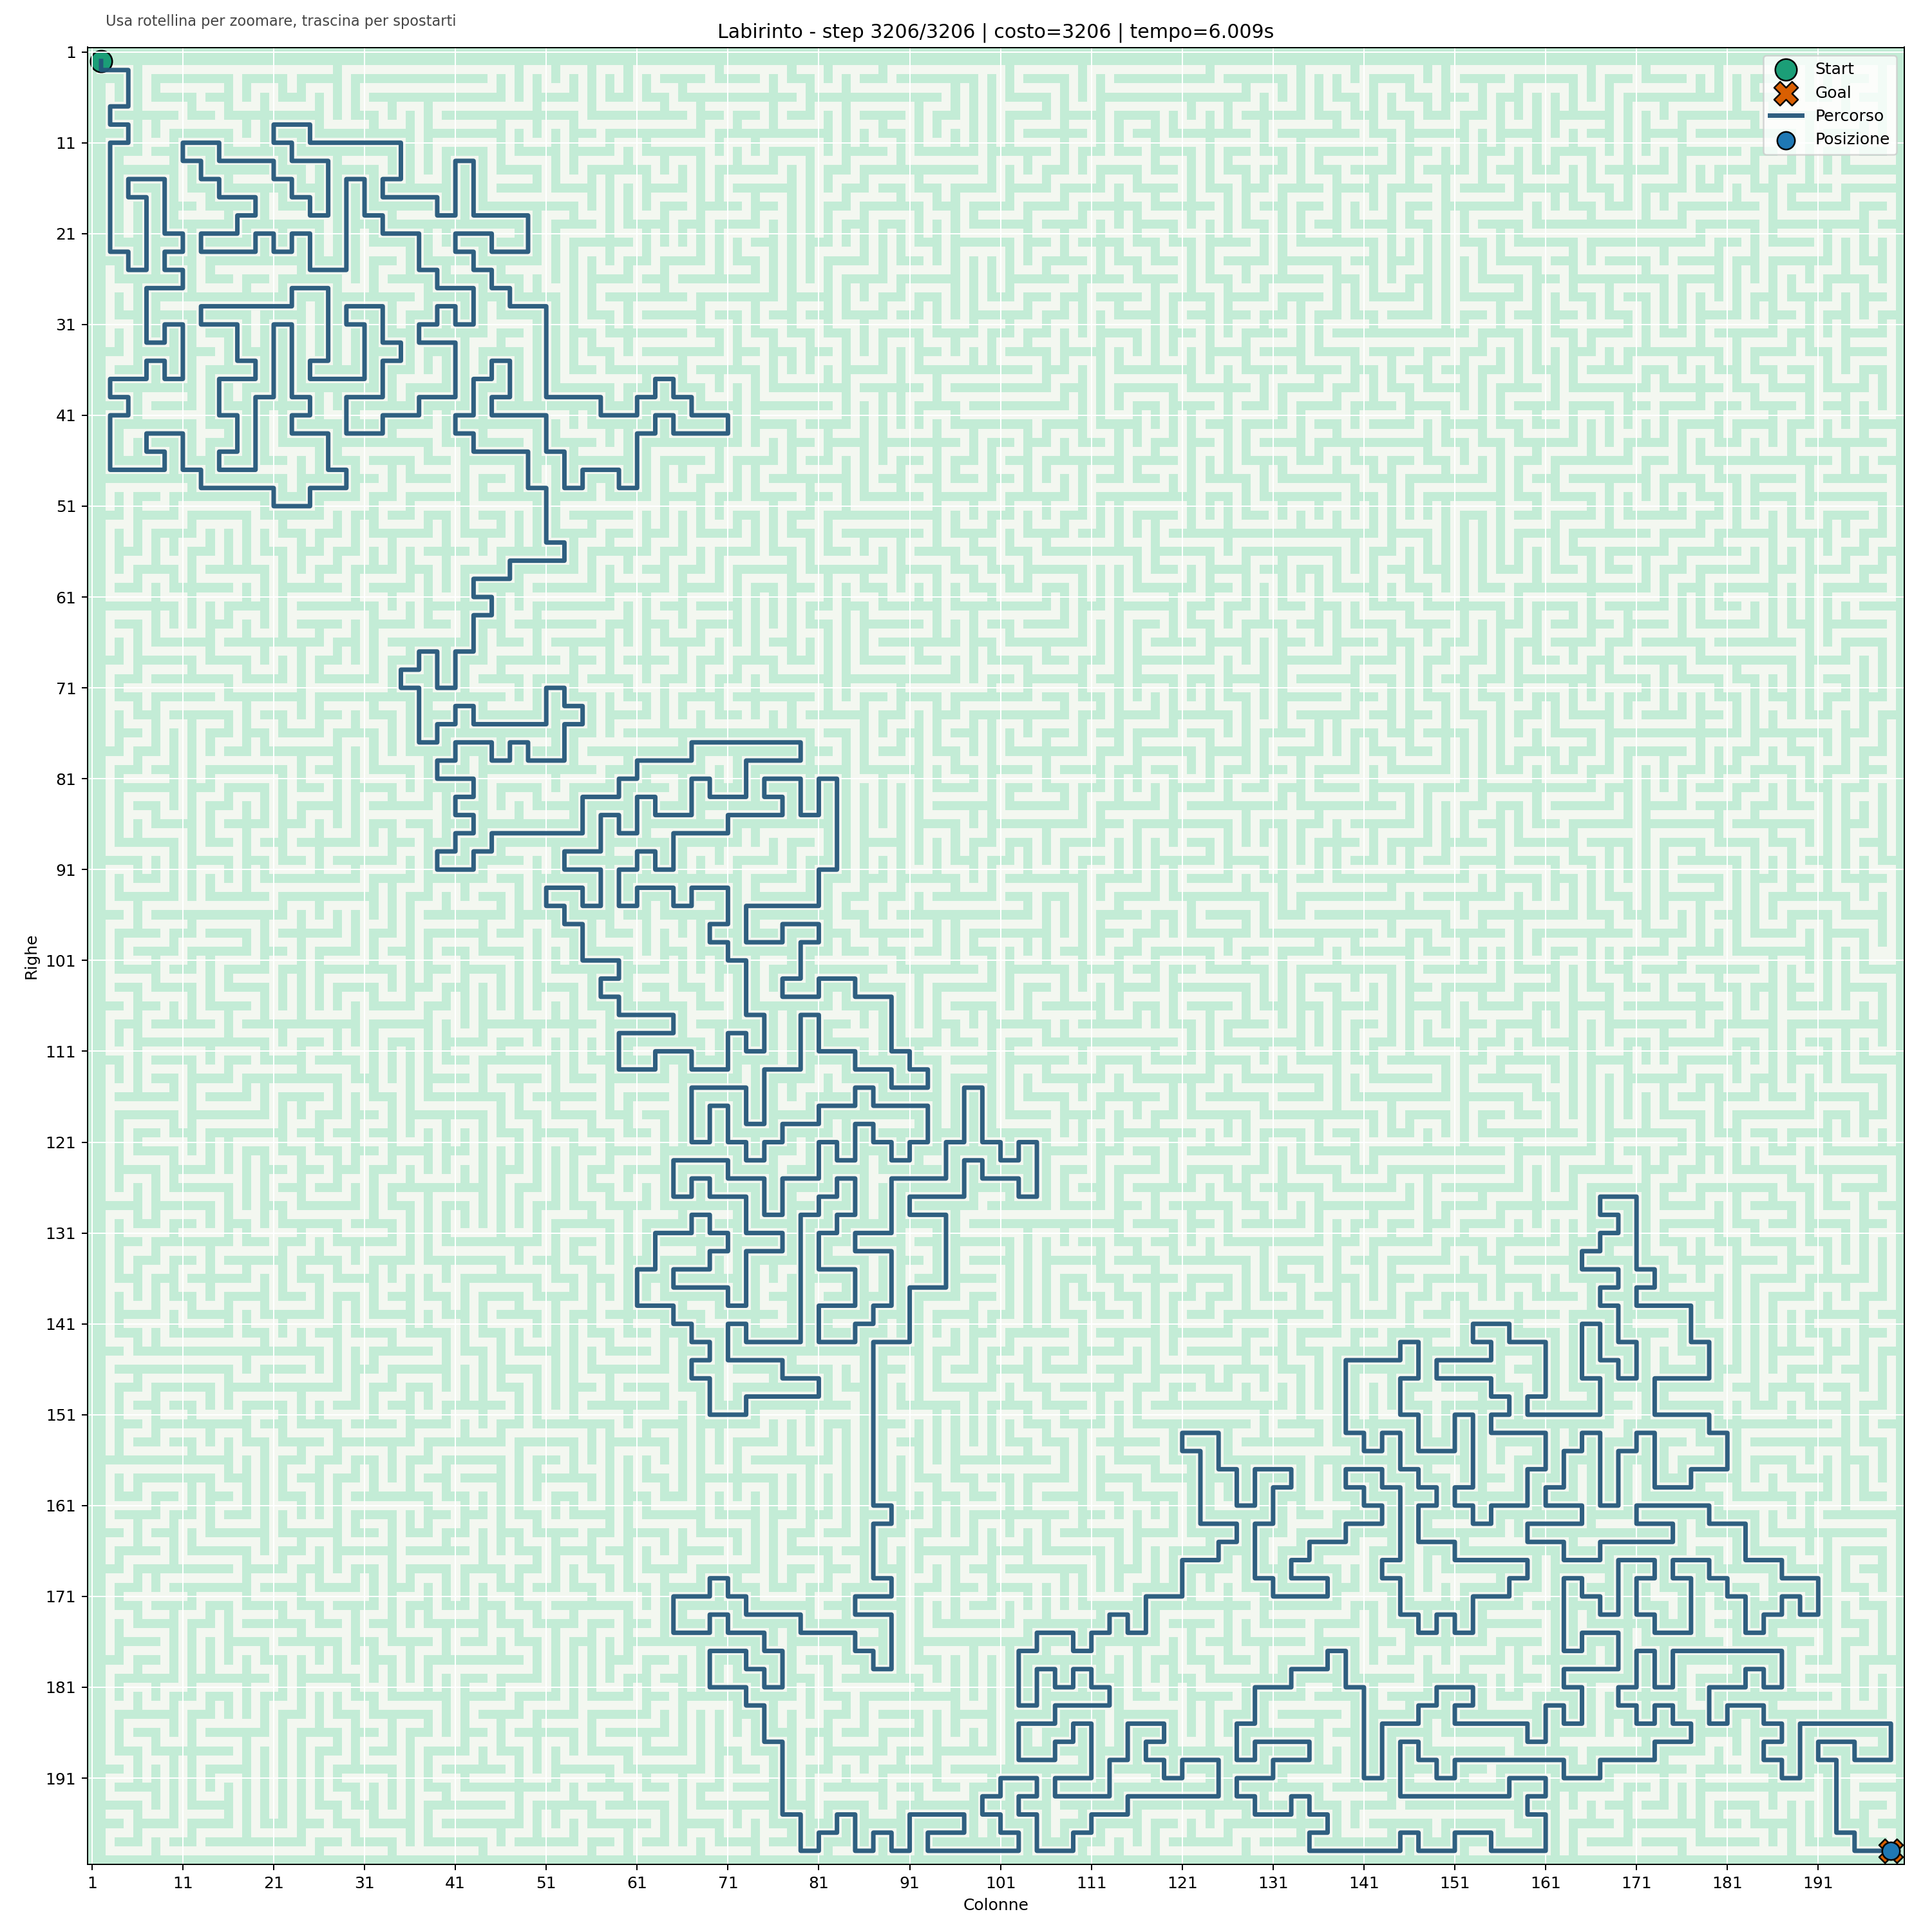

In [1]:
from pathlib import Path
import subprocess
import sys

from IPython.display import Image, display

project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'src/prolog/app/main.pl').exists()
)
out_dir = project_root / 'docs/figures'
out_dir.mkdir(parents=True, exist_ok=True)
script = project_root / 'tools/python/visualizza_risultati.py'

outfile = out_dir / 'labirinto_astar.png'
subprocess.run(
    [sys.executable, str(script), '--domain', 'labirinto', '--algo', 'astar', '--save', str(outfile)],
    check=True,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)

display(Image(filename=str(outfile)))


## Come eseguire

```bash
python tools/python/visualizza_risultati.py --domain labirinto --algo astar --save docs/figures/labirinto_astar.png
```

Lo script legge i domini in `src/prolog/domini/` e salva la visualizzazione nel percorso indicato.